# Chapter 4 — attention and Shapley attribution of the MIL model

Interrogates what the trained attention-MIL model actually uses, directly from the Task 1 checkpoints
(`outputs/review/task1/<run_id>/checkpoints/<run_id>_best.pt`, inner-validation selection, 3 seeds per
direction). Unlike the earlier version of this notebook, every attribution here comes from the MIL model
itself — no surrogate model is fitted.

| Section | Figure / table | What it answers |
|---|---|---|
| 1 | Per-cell attention from the checkpoints | How concentrated is attention? (no cell is zeroed) |
| 2 | Attention drivers | Which features make a cell win attention within its group? |
| 3 | **Shapley values of the bag age score** | Which features move the held-out score, and in which direction? |
| 4 | Shapley values of the attention score | What drives attention, computed exactly from the attention branch |
| 5 | Score vs attention attribution | Do the features that set the score also set attention? |

**Shapley definition (section 3).** Players are the 58 input features. A feature is *absent* when its values
in every cell of the bag are swapped for the values of the matching cells of a background bag drawn from the
*training* line (interventional Shapley, averaged over background bags). The value is the model's continuous
score $\hat s$ = E[rank]/(K−1) from `scoring.score_from_logits`. By the efficiency property the values of a bag
sum to $\hat s$(bag) − mean $\hat s$(background), so a feature's value is its contribution, in score units, to
moving the bag away from the average training-line bag. Values are estimated with antithetic permutation
sampling; the five feature blocks are also computed exactly (all 32 coalitions).

Inputs are in z units (each run's own training-line scaler) and the block weights are applied inside the model
wrapper, so manual and latent Shapley values are directly comparable — no block-weight correction is needed.

Set `REPO` below to the root of the MILAgeScore repository. Shapley values are cached in
`outputs/review/shapley/`; set `RECOMPUTE = True` to rebuild them.

In [1]:
from pathlib import Path
import sys, re, io, math, pickle, warnings, contextlib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)

# ── paths ────────────────────────────────────────────────────────────────────
REPO     = None                                   # root of the MILAgeScore repo; None = search upwards from the notebook folder
if REPO is None: REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "model.py").exists() and (p / "data" / "processed").is_dir()), Path.cwd())
REPO     = Path(REPO).resolve()
REVIEW   = REPO / "outputs" / "review"
TASK1    = REVIEW / "task1"                       # <run_id>/checkpoints, <run_id>/logs/scalers, selected_epochs.csv
SHAP_DIR = REVIEW / "shapley"                     # cache for attention and Shapley tables
PROC     = REPO / "data" / "processed"
FIG_DIR  = REPO / "thesis_figures" / "chapter4"
TAB_DIR  = REPO / "thesis_tables" / "chapter4"
for p in (PROC / "features_manual.npy", PROC / "labels.csv", TASK1): assert p.exists(), f"not found: {p} (cwd = {Path.cwd()}); set REPO to the repo root"
for d in (SHAP_DIR, FIG_DIR, TAB_DIR): d.mkdir(parents=True, exist_ok=True)
print("repo:", REPO)
if str(REPO) not in sys.path: sys.path.insert(0, str(REPO))
from src.model import build_model
from src.scoring import score_from_logits

# ── analysis settings ────────────────────────────────────────────────────────
RECOMPUTE      = False     # True: ignore cached tables in SHAP_DIR
N_ATT_BAGS     = 50        # bags per (line, passage) group for per-cell mean attention
N_SHAP_BAGS    = 4         # held-out bags explained per passage and run
N_BG_BAGS      = 8         # training-line background bags
N_PERM         = 10        # permutations per bag (antithetic pairs, so even)
N_ATT_CELLS    = 200       # held-out cells per run for attention Shapley
N_BG_CELLS     = 32        # training-line background cells for attention Shapley
DEVICE         = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── plotting style (identical to notebook 02) ────────────────────────────────
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
C_LINE  = {1: "#1b6ca8", 2: "#d1495b"}
C_BLOCK = {"shape": "#d1495b", "intensity": "#2e8b57", "ratio": "#8e6bbf",
           "texture-distribution": "#e08e0b", "latent": "#1b6ca8"}
BLOCKS  = list(C_BLOCK)

def savefig(fig, name):
    for ext in ("png", "pdf"): fig.savefig(FIG_DIR / f"{name}.{ext}")
    print(f"saved {FIG_DIR / name}.png/.pdf")

def savetab(df, name, **kw):
    df.to_csv(TAB_DIR / f"{name}.csv", **kw); print(f"saved {TAB_DIR / name}.csv")

def block_of(f):
    if f.startswith("latent"): return "latent"
    if f in ("Area", "Perimeter", "Eccentricity", "Circularity", "MinAxisLength", "MaxAxisLength", "AspectRatio", "Extent"): return "shape"
    if f.startswith("ratio"): return "ratio"
    if f.startswith(("mean", "rawIntDen")): return "intensity"
    return "texture-distribution"

def block_legend(ax, **kw):
    ax.legend(handles=[mpl.patches.Patch(color=v, label=k) for k, v in C_BLOCK.items()], **kw)
print("device:", DEVICE)

repo: C:\Users\goofy\PycharmProjects\MILAgeScore
device: cuda


## Data and checkpoints

The processed arrays are the inputs every run was trained on. Each run is restored with **its own** scalers
(`logs/scalers/`, fitted on the training line only); the copies in `data/processed/` are overwritten by
whichever run trained last and must not be used here. Block weights, bag size and the per-well cap are read
from the configuration stored in the checkpoint.

In [2]:
Xm, Xl = np.load(PROC / "features_manual.npy"), np.load(PROC / "features_latent.npy")
manual_cols = pickle.load(open(PROC / "manual_cols.pkl", "rb")); latent_cols = pickle.load(open(PROC / "latent_cols.pkl", "rb"))
lab = pd.read_csv(PROC / "labels.csv")
lab["cell_line"] = pd.to_numeric(lab["cell_line"], errors="coerce").astype(int); lab["passage"] = lab["passage"].astype(int)
assert len(Xm) == len(Xl) == len(lab), "feature arrays and labels are not row-aligned"
FEATS = list(manual_cols) + list(latent_cols); D = len(FEATS)
BLK = np.array([block_of(f) for f in FEATS])
print(f"cells {len(lab):,} | wells {lab.well_name.nunique()} | features {D} ({len(manual_cols)} manual, {len(latent_cols)} latent)")
print(pd.Series(BLK).value_counts().to_string())

def load_run(rid):
    run = TASK1 / rid
    ckpt = torch.load(run / "checkpoints" / f"{rid}_best.pt", map_location=DEVICE, weights_only=False)
    cfg, enc = ckpt["cfg"], ckpt["encoder"]
    fs = cfg["data"].get("feature_set", "both").lower()
    assert fs == "both", f"{rid}: feature_set={fs}; this notebook expects the all-feature model"
    sm = pickle.load(open(run / "logs" / "scalers" / "scaler_manual.pkl", "rb"))
    sl = pickle.load(open(run / "logs" / "scalers" / "scaler_latent.pkl", "rb"))
    n_m, n_l = len(manual_cols), len(latent_cols)
    w_m = float(cfg["bags"].get("w_manual", math.sqrt(n_l / n_m))); w_l = float(cfg["bags"].get("w_latent", 1.0))
    in_f = ckpt["model_state"]["encoder.encoder.0.weight"].shape[1]
    assert in_f == D, f"{rid}: checkpoint expects {in_f} features, processed data has {D}"
    with contextlib.redirect_stdout(io.StringIO()): model = build_model(cfg, in_features=in_f, num_classes=enc.num_classes)
    model.load_state_dict(ckpt["model_state"]); model.to(DEVICE).eval()
    Z = np.hstack([sm.transform(Xm), sl.transform(Xl)]).astype(np.float32)        # z units
    ho = int(re.search(r"HO_L(\d)", rid).group(1))
    return dict(rid=rid, model=model, K=enc.num_classes, Z=Z, ho=ho, train=3 - ho, seed=int(re.search(r"seed(\d+)", rid).group(1)),
                W=torch.tensor(np.r_[np.full(n_m, w_m), np.full(n_l, w_l)], dtype=torch.float32, device=DEVICE),
                cpb=int(cfg["bags"]["cells_per_bag"]), mwf=float(cfg["bags"]["max_well_fraction"]), epoch=ckpt.get("epoch"))

f_sel = TASK1 / "selected_epochs.csv"
RUNS = pd.read_csv(f_sel)["run_id"].tolist() if f_sel.exists() else sorted(p.name for p in TASK1.glob("loco_HO_L*_seed*") if p.is_dir())
runs = {rid: load_run(rid) for rid in RUNS}
pd.DataFrame([{k: r[k] for k in ("rid", "ho", "train", "seed", "epoch", "K", "cpb", "mwf")} | {"w_manual": float(r["W"][0]), "w_latent": float(r["W"][-1])}
              for r in runs.values()])

cells 16,505 | wells 160 | features 58 (42 manual, 16 latent)
texture-distribution    19
latent                  16
intensity               10
shape                    8
ratio                    5


,rid,ho,train,seed,epoch,K,cpb,mwf,w_manual,w_latent
0,loco_HO_L1_seed0,1,2,0,5,10,100,0.5,0.617213,1.0
1,loco_HO_L1_seed1,1,2,1,36,10,100,0.5,0.617213,1.0
2,loco_HO_L1_seed2,1,2,2,7,10,100,0.5,0.617213,1.0
3,loco_HO_L2_seed0,2,1,0,13,10,30,0.5,0.617213,1.0
4,loco_HO_L2_seed1,2,1,1,16,10,30,0.5,0.617213,1.0
5,loco_HO_L2_seed2,2,1,2,36,10,30,0.5,0.617213,1.0


## Model wrappers and bag sampling

`sample_bags` reproduces the sampler in `evaluate.py` (cells pooled over the wells of one line × passage group,
capped per well, topped up with replacement). `bag_scores` returns $\hat s$ through `score_from_logits`, the same
path as the reported trajectories. `attention_logit` is the pre-softmax gated-attention score; it depends only
on the cell itself, so its Shapley values need no bag context.

In [3]:
GROUPS = {k: g.index.to_numpy() for k, g in lab.groupby(["cell_line", "passage"])}
WELLS  = lab["well_name"].to_numpy()

def sample_bags(idx, n, cpb, mwf, rng):
    cap = int(np.ceil(mwf * cpb)); w = WELLS[idx]; out = []
    for _ in range(n):
        pool = np.concatenate([rng.choice(idx[w == u], size=min((w == u).sum(), cap), replace=False) for u in np.unique(w)])
        out.append(pool[rng.choice(len(pool), size=cpb, replace=len(pool) < cpb)])
    return np.stack(out)                                                                  # (n, cpb) cell indices

@torch.no_grad()
def bag_scores(r, x, chunk=512):
    # x: (..., N, D) z-unit tensor -> continuous score per bag, shape (...)
    lead, out = x.shape[:-2], []
    x = x.reshape(-1, *x.shape[-2:])
    for i in range(0, len(x), chunk):
        logits, _ = r["model"](x[i:i + chunk] * r["W"]); out.append(score_from_logits(logits, r["K"]))
    return torch.cat(out).reshape(lead)

@torch.no_grad()
def bag_attention(r, x):
    _, a = r["model"](x * r["W"]); return a                                               # (B, N), sums to 1 per bag

@torch.no_grad()
def attention_logit(r, x, chunk=65536):
    # x: (M, D) z-unit cells -> pre-softmax attention score per cell
    m, out = r["model"], []
    for i in range(0, len(x), chunk):
        h = m.encoder((x[i:i + chunk] * r["W"]).unsqueeze(0)).squeeze(0)
        out.append(m.aggregator.w(torch.tanh(m.aggregator.V(h)) * torch.sigmoid(m.aggregator.U(h))).squeeze(-1))
    return torch.cat(out)

def T(a): return torch.as_tensor(a, dtype=torch.float32, device=DEVICE)

# 1 · Per-cell attention from the Task 1 checkpoints

Each cell's attention is averaged over every bag it appears in (`N_ATT_BAGS` bags per group), then expressed
relative to uniform weighting: `rel = α × bag size`, so 1 means the cell gets exactly its share. This replaces the
legacy `explain.py` files, whose checkpoints were selected on the held-out line. **No cell receives zero
attention** — the minimum relative weight is about one half — so the "zeroed-out" analysis of the earlier version
is replaced by a top- versus bottom-decile contrast.

In [6]:
def cell_attention(r, seed=0):
    f = SHAP_DIR / f"attention_{r['rid']}.csv"
    if f.exists() and not RECOMPUTE: return pd.read_csv(f)["rel"].to_numpy()
    rng, s, c = np.random.default_rng(seed), np.zeros(len(lab)), np.zeros(len(lab))
    Zt = T(r["Z"])
    for idx in GROUPS.values():
        b = sample_bags(idx, N_ATT_BAGS, r["cpb"], r["mwf"], rng)
        a = bag_attention(r, Zt[torch.as_tensor(b, device=DEVICE)]).cpu().numpy() * r["cpb"]
        np.add.at(s, b.ravel(), a.ravel()); np.add.at(c, b.ravel(), 1)
    rel = np.where(c > 0, s / np.maximum(c, 1), np.nan)
    pd.DataFrame({"rel": rel, "n_bags": c}).to_csv(f, index=False); return rel

att = lab[["well_name", "cell_line", "passage"]].copy()
for rid, r in runs.items(): att[rid] = cell_attention(r)
for ho in (1, 2):                                                     # seed mean per training direction
    att[f"rel_HO{ho}"] = att[[rid for rid in runs if runs[rid]["ho"] == ho]].mean(axis=1)
    att[f"heldout_HO{ho}"] = att.cell_line.eq(ho)

print("held-out cells never sampled into a bag:", {ho: f"{att.loc[att[f'heldout_HO{ho}'], f'rel_HO{ho}'].isna().mean():.1%}" for ho in (1, 2)})
q = pd.DataFrame({f"held-out line {ho}": att.loc[att[f"heldout_HO{ho}"], f"rel_HO{ho}"].quantile([0, .01, .05, .5, .95, .99, 1]) for ho in (1, 2)}).T
q["sd across seeds (median cell)"] = [att.loc[att[f"heldout_HO{ho}"], [k for k in runs if runs[k]["ho"] == ho]].std(axis=1).median() for ho in (1, 2)]
savetab(q.round(3), "attention_relative_quantiles_task1"); q.round(2)

held-out cells never sampled into a bag: {1: '1.5%', 2: '16.9%'}
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\attention_relative_quantiles_task1.csv


,0.0,0.01,0.05,0.5,0.95,0.99,1.0,sd across seeds (median cell)
held-out line 1,0.48,0.61,0.70,0.98,1.36,1.59,2.24,0.13
held-out line 2,0.40,0.58,0.68,0.98,1.40,1.65,2.43,0.12


saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\B4_attention_distribution_task1.png/.pdf


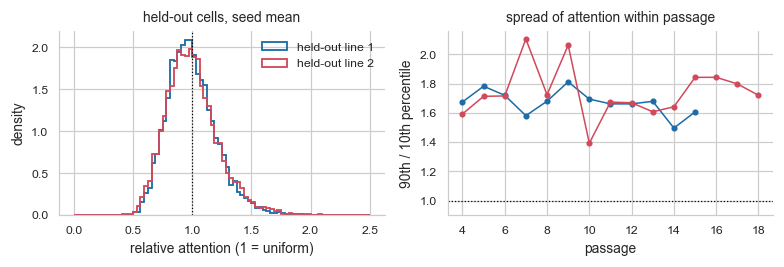

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5))
ax = axes[0]; bins = np.linspace(0, 2.5, 81)
for ho in (1, 2):
    v = att.loc[att[f"heldout_HO{ho}"], f"rel_HO{ho}"]
    ax.hist(v, bins=bins, histtype="step", lw=1.2, density=True, color=C_LINE[ho], label=f"held-out line {ho}")
ax.axvline(1, color="k", ls=":", lw=0.8); ax.set_xlabel("relative attention (1 = uniform)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("held-out cells, seed mean")
ax = axes[1]
for ho in (1, 2):
    d = att[att[f"heldout_HO{ho}"]].groupby("passage")[f"rel_HO{ho}"]
    ax.plot(d.quantile(.9).index, d.quantile(.9) / d.quantile(.1), "o-", ms=3, lw=1, color=C_LINE[ho], label=f"held-out line {ho}")
ax.axhline(1, color="k", ls=":", lw=0.8); ax.set_xlabel("passage"); ax.set_ylabel("90th / 10th percentile"); ax.set_ylim(0.9, None)
ax.set_title("spread of attention within passage")
fig.tight_layout(); savefig(fig, "B4_attention_distribution_task1")

# 2 · What makes a cell win attention?

Attention is a softmax within the bag, so it is analysed **within** each line × passage group:
(a) within-group Spearman correlation between each feature and relative attention;
(b) effect size between the top and bottom attention decile of each group (z units, pooled SD);
(c) how well the input features predict top- versus bottom-decile membership (logistic regression,
cross-validated with wells kept intact). With 1 000+ cells per group, effect sizes matter, not p-values.

In [8]:
def attention_drivers(ho):
    d = att[att[f"heldout_HO{ho}"] & att[f"rel_HO{ho}"].notna()].copy(); X = pd.DataFrame(np.hstack([Xm, Xl])[d.index], columns=FEATS, index=d.index)
    g = d.groupby("passage"); a_r = g[f"rel_HO{ho}"].rank(pct=True)
    rho = pd.Series({f: spearmanr(X[f].groupby(d.passage).rank(pct=True), a_r)[0] for f in FEATS})
    dec = g[f"rel_HO{ho}"].transform(lambda v: pd.qcut(v.rank(method="first"), 10, labels=False))
    hi, lo = dec.eq(9), dec.eq(0)
    sp = np.sqrt((X[hi].var() + X[lo].var()) / 2)
    out = pd.DataFrame({"rho_within": rho, "d_top_bottom": (X[hi].mean() - X[lo].mean()) / sp, "block": [block_of(f) for f in FEATS]})
    sel = hi | lo; y = hi[sel].astype(int).to_numpy()
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    auc = cross_val_score(clf, X[sel], y, groups=d.loc[sel, "well_name"], cv=StratifiedGroupKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return out, auc

drv, aucs = {}, {}
for ho in (1, 2): drv[ho], aucs[ho] = attention_drivers(ho)
drivers = pd.concat({f"held-out line {ho}": drv[ho] for ho in (1, 2)}, axis=1)
savetab(drivers.round(4), "attention_drivers_task1")
for ho in (1, 2): print(f"held-out line {ho}: top vs bottom attention decile, grouped 5-fold ROC-AUC = {aucs[ho].mean():.3f} ± {aucs[ho].std():.3f}")
pd.concat({ho: drv[ho].reindex(drv[ho].rho_within.abs().sort_values(ascending=False).index).head(12) for ho in (1, 2)}, axis=1).round(3)

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\attention_drivers_task1.csv
held-out line 1: top vs bottom attention decile, grouped 5-fold ROC-AUC = 0.999 ± 0.001
held-out line 2: top vs bottom attention decile, grouped 5-fold ROC-AUC = 0.986 ± 0.004


1                                             2  \
             rho_within d_top_bottom                 block rho_within   
ratio6            0.535        2.072                 ratio        NaN   
mean_3           -0.522       -2.051             intensity     -0.380   
ratio5           -0.509       -1.925                 ratio        NaN   
mean_14          -0.499       -2.018             intensity     -0.217   
var_40per_11     -0.495       -2.049  texture-distribution     -0.284   
ratio3            0.492        1.947                 ratio        NaN   
var_20per_5      -0.467       -1.850  texture-distribution     -0.340   
mean_20per_2     -0.460       -1.758             intensity     -0.417   
ratio4           -0.455       -1.629                 ratio     -0.497   
ratio8            0.448        1.669                 ratio        NaN   
var_40per_2      -0.437       -1.740  texture-distribution     -0.409   
var_20per_14     -0.426       -1.635  texture-distribution        NaN   
var_20per_1         NaN          NaN                   NaN     -0.404   
mean_1              NaN          NaN                   NaN     -0.390   
rawIntDen_1         NaN          NaN                   NaN     -0.276   
Circularity         NaN          NaN                   NaN      0.238   
skew_1              NaN          NaN                   NaN     -0.194   

                                                 
             d_top_bottom                 block  
ratio6                NaN                   NaN  
mean_3             -1.497             intensity  
ratio5                NaN                   NaN  
mean_14            -0.837             intensity  
var_40per_11       -1.161  texture-distribution  
ratio3                NaN                   NaN  
var_20per_5        -1.395  texture-distribution  
mean_20per_2       -1.657             intensity  
ratio4             -1.697                 ratio  
ratio8                NaN                   NaN  
var_40per_2        -1.705  texture-distribution  
var_20per_14          NaN                   NaN  
var_20per_1        -1.678  texture-distribution  
mean_1             -1.491             intensity  
rawIntDen_1        -1.004             intensity  
Circularity         0.802                 shape  
skew_1             -0.724  texture-distribution

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\B5_attention_drivers_task1.png/.pdf


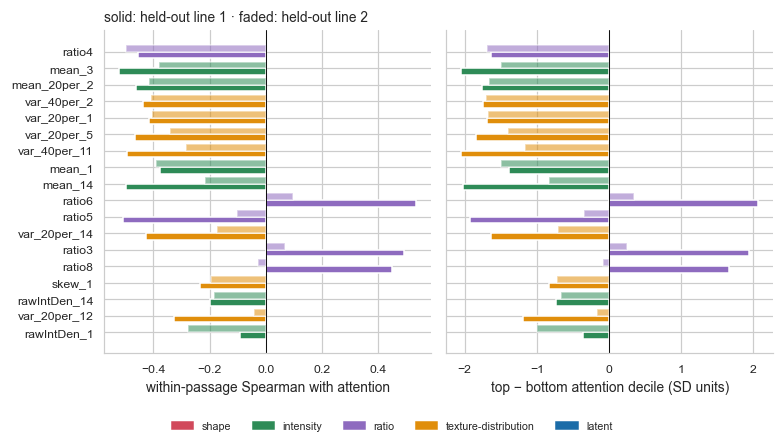

In [9]:
top = (drv[1].rho_within.abs() + drv[2].rho_within.abs()).nlargest(18).index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 4.0), sharey=True)
for ax, (col, lab_) in zip(axes, [("rho_within", r"within-passage Spearman with attention"), ("d_top_bottom", "top − bottom attention decile (SD units)")]):
    y = np.arange(len(top))
    for k, ho in enumerate((1, 2)):
        ax.barh(y + (k - 0.5) * 0.4, drv[ho].loc[top, col], height=0.4, color=[C_BLOCK[block_of(f)] for f in top], alpha=1 if ho == 1 else 0.55)
    ax.axvline(0, color="k", lw=0.6); ax.set_xlabel(lab_)
axes[0].set_yticks(y); axes[0].set_yticklabels(top)
axes[0].set_title("solid: held-out line 1 · faded: held-out line 2", loc="left")
fig.tight_layout(rect=(0, 0.06, 1, 1)); block_legend(fig, ncol=5, loc="lower center", fontsize=7)
savefig(fig, "B5_attention_drivers_task1")

# 3 · Shapley values of the bag age score

For each run, `N_SHAP_BAGS` bags per passage of the **held-out** line are explained against `N_BG_BAGS`
training-line background bags (one random passage each). `bag_shapley` evaluates the value function on every
prefix of each permutation in a single batched pass, so the per-bag values satisfy efficiency exactly:
`phi.sum() == s_hat − base`. The block Shapley values use all 2⁵ coalitions of the five feature blocks and are
exact for the chosen background.

In [10]:
def value_fn(r, bag, bg):
    # v(masks): mean score over background bags with absent features (mask 0) replaced by background values
    def v(M, chunk=64):
        out = []
        for i in range(0, len(M), chunk):
            m = M[i:i + chunk, None, None, :]
            out.append(bag_scores(r, torch.where(m, bag[None, None], bg[None])).mean(1))
        return torch.cat(out)
    return v

def bag_shapley(v, rng, n_perm=N_PERM):
    P = []
    for _ in range(n_perm // 2): p = rng.permutation(D); P += [p, p[::-1]]
    P = np.array(P); rank = np.argsort(P, axis=1)                                         # position of each feature in each permutation
    M = rank[:, None, :] < np.arange(D + 1)[None, :, None]                                # (n_perm, D+1, D) prefix masks
    val = v(torch.as_tensor(M.reshape(-1, D), device=DEVICE)).cpu().numpy().reshape(len(P), D + 1)
    phi = np.zeros(D); np.add.at(phi, P.ravel(), np.diff(val, axis=1).ravel())
    return phi / len(P), val[:, 0].mean(), val[:, -1].mean()

COAL = np.array([[(c >> b) & 1 for b in range(len(BLOCKS))] for c in range(2 ** len(BLOCKS))], bool)
def block_shapley(v):
    Mf = torch.as_tensor(np.stack([np.isin(BLK, [BLOCKS[b] for b in np.where(c)[0]]) for c in COAL]), device=DEVICE)
    val = dict(zip(map(tuple, COAL), v(Mf).cpu().numpy())); n = len(BLOCKS); phi = np.zeros(n)
    for c in COAL:
        for b in np.where(~c)[0]:
            s = c.sum(); w = math.factorial(s) * math.factorial(n - s - 1) / math.factorial(n)
            cb = c.copy(); cb[b] = True; phi[b] += w * (val[tuple(cb)] - val[tuple(c)])
    return phi

def shapley_run(r, seed=0):
    f = SHAP_DIR / f"shapley_score_{r['rid']}.csv"
    if f.exists() and not RECOMPUTE: return pd.read_csv(f)
    rng = np.random.default_rng(seed); Zt = T(r["Z"])
    bg_groups = [k for k in GROUPS if k[0] == r["train"]]
    bg_idx = np.concatenate([sample_bags(GROUPS[bg_groups[i]], 1, r["cpb"], r["mwf"], rng) for i in rng.choice(len(bg_groups), N_BG_BAGS)])
    bg = Zt[torch.as_tensor(bg_idx, device=DEVICE)]
    rows = []
    for (line, p), idx in GROUPS.items():
        if line != r["ho"]: continue
        for b in sample_bags(idx, N_SHAP_BAGS, r["cpb"], r["mwf"], rng):
            bag = Zt[torch.as_tensor(b, device=DEVICE)]; v = value_fn(r, bag, bg)
            phi, base, full = bag_shapley(v, rng); phib = block_shapley(v)
            s_hat = float(bag_scores(r, bag[None])[0])
            rows.append({"run_id": r["rid"], "held_out_line": r["ho"], "seed": r["seed"], "passage": p, "s_hat": s_hat, "base": base, "v_full": full}
                        | {f"phi_{f}": x for f, x in zip(FEATS, phi)} | {f"blk_{k}": x for k, x in zip(BLOCKS, phib)}
                        | {f"z_{f}": x for f, x in zip(FEATS, r["Z"][b].mean(0))})
    df = pd.DataFrame(rows); df.to_csv(f, index=False); return df

sh = pd.concat([shapley_run(r) for r in runs.values()], ignore_index=True)
PHI, ZB = sh[[f"phi_{f}" for f in FEATS]].to_numpy(), sh[[f"z_{f}" for f in FEATS]].to_numpy()
err = np.abs(PHI.sum(1) - (sh.v_full - sh.base)).max()
print(f"bags explained: {len(sh)} | efficiency check max |Σφ − (v_full − base)| = {err:.2e}")
print(f"v_full vs s_hat (background replacement of no feature must equal the bag score): max diff {np.abs(sh.v_full - sh.s_hat).max():.2e}")
sh.groupby(["held_out_line", "seed"]).agg(bags=("s_hat", "size"), base=("base", "mean"), s_hat=("s_hat", "mean")).round(3)

bags explained: 324 | efficiency check max |Σφ − (v_full − base)| = 1.19e-07
v_full vs s_hat (background replacement of no feature must equal the bag score): max diff 2.38e-07


bags   base  s_hat
held_out_line seed                    
1             0       48  0.307  0.441
              1       48  0.319  0.447
              2       48  0.312  0.456
2             0       60  0.332  0.518
              1       60  0.333  0.540
              2       60  0.333  0.518

In [11]:
# Feature ranking: mean |φ| per run, then mean ± SD over seeds, per training direction
per_run = pd.DataFrame(np.abs(PHI), columns=FEATS).groupby([sh.held_out_line, sh.seed]).mean()
signed  = pd.DataFrame(PHI, columns=FEATS).groupby([sh.held_out_line, sh.seed]).mean()
imp = pd.concat({f"HO{ho}_{s}": per_run.xs(ho).agg(["mean", "std"]).T.iloc[:, i] for ho in (1, 2) for i, s in enumerate(("mean_abs_phi", "sd_seeds"))}, axis=1)
for ho in (1, 2):
    imp[f"HO{ho}_mean_phi"] = signed.xs(ho).mean()
    imp[f"HO{ho}_rho_z_phi"] = [spearmanr(ZB[sh.held_out_line.eq(ho), j], PHI[sh.held_out_line.eq(ho), j])[0] for j in range(D)]   # direction of effect
imp["block"] = [block_of(f) for f in FEATS]
imp = imp.sort_values("HO1_mean_abs_phi", ascending=False)
savetab(imp.round(5), "shapley_score_feature_importance")
blk_share = pd.DataFrame({f"held-out line {ho}": imp.groupby("block")[f"HO{ho}_mean_abs_phi"].sum() / imp[f"HO{ho}_mean_abs_phi"].sum() for ho in (1, 2)})
blk_share["n_features"] = imp.block.value_counts()
savetab(blk_share.round(3), "shapley_score_block_share"); display(blk_share.round(3))
imp.head(15).round(4)

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\shapley_score_feature_importance.csv
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\shapley_score_block_share.csv


,held-out line 1,held-out line 2,n_features
block,,,
intensity,0.169,0.161,10
latent,0.130,0.106,16
ratio,0.199,0.253,5
shape,0.208,0.185,8
texture-distribution,0.293,0.295,19


,HO1_mean_abs_phi,HO1_sd_seeds,HO2_mean_abs_phi,HO2_sd_seeds,HO1_mean_phi,HO1_rho_z_phi,HO2_mean_phi,HO2_rho_z_phi,block
ratio5,0.0332,0.0069,0.0746,0.0088,0.0027,-0.8850,0.0559,-0.8533,ratio
Area,0.0298,0.0162,0.0435,0.0138,0.0197,0.6618,0.0111,0.9258,shape
Perimeter,0.0287,0.0130,0.0094,0.0023,0.0224,0.8212,0.0009,0.7746,shape
MinAxisLength,0.0259,0.0035,0.0264,0.0009,0.0226,0.8122,0.0023,0.9161,shape
ratio8,0.0226,0.0094,0.0172,0.0044,0.0069,0.7885,0.0060,0.4350,ratio
ratio4,0.0215,0.0059,0.0268,0.0030,0.0168,-0.3345,0.0184,0.2794,ratio
kurt_40per_1,0.0214,0.0063,0.0088,0.0023,0.0012,-0.8668,0.0001,-0.3838,texture-distribution
mean_1,0.0209,0.0099,0.0096,0.0022,-0.0174,0.8185,0.0027,0.6052,intensity
ratio6,0.0202,0.0099,0.0366,0.0068,0.0053,0.6528,0.0228,0.7930,ratio
ratio3,0.0183,0.0086,0.0102,0.0026,-0.0018,0.8638,0.0041,0.4429,ratio


**3a. Summary (beeswarm).** One point per explained bag (all seeds pooled). Horizontal position is the
feature's contribution to the bag score; colour is the bag's mean value of that feature relative to the training
line (z units). Features are ordered by mean |φ| over both directions.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S1_shapley_score_beeswarm.png/.pdf


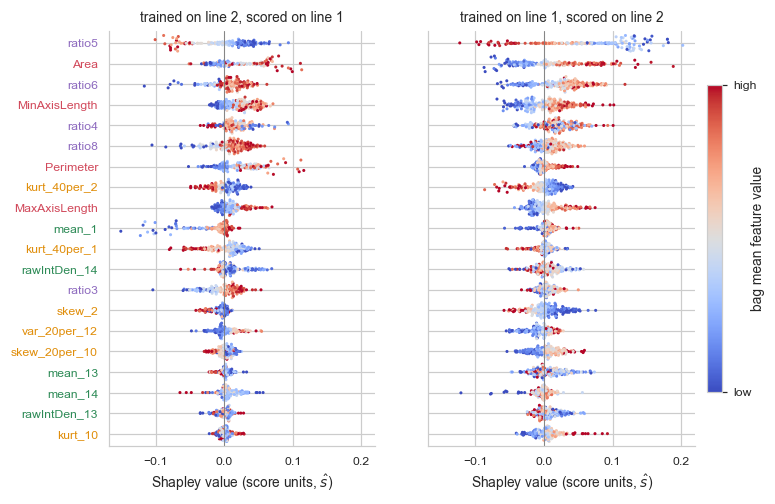

In [12]:
def beeswarm(ax, phi, z, feats, n_bins=60, width=0.38, cmap="coolwarm"):
    lo, hi = np.nanpercentile(phi, [0.5, 99.5]); edges = np.linspace(lo, hi, n_bins + 1)
    for i, j in enumerate(feats):
        x, c = phi[:, j], z[:, j]
        cl = np.clip((c - np.nanpercentile(c, 5)) / (np.nanpercentile(c, 95) - np.nanpercentile(c, 5) + 1e-12), 0, 1)
        k = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1); y = np.zeros(len(x))
        for b in np.unique(k):
            m = np.where(k == b)[0]; n = len(m); off = (np.arange(n) - (n - 1) / 2)
            y[m[np.random.default_rng(b).permutation(n)]] = off
        y = y / max(np.abs(y).max(), 1) * width
        ax.scatter(x, i + y, c=cl, cmap=cmap, vmin=0, vmax=1, s=4, lw=0, rasterized=True)
    ax.axvline(0, color="0.5", lw=0.6); ax.set_yticks(range(len(feats))); ax.set_ylim(-0.6, len(feats) - 0.4)

N_TOP = 20
order = (imp.HO1_mean_abs_phi + imp.HO2_mean_abs_phi).sort_values(ascending=False).index[:N_TOP][::-1]
jj = [FEATS.index(f) for f in order]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 0.19 * N_TOP + 1.1), sharey=True, sharex=True)
for ax, ho in zip(axes, (1, 2)):
    m = sh.held_out_line.eq(ho).to_numpy(); beeswarm(ax, PHI[m], ZB[m], jj)
    ax.set_title(f"trained on line {3 - ho}, scored on line {ho}"); ax.set_xlabel(r"Shapley value (score units, $\hat{s}$)")
axes[0].set_yticklabels(order)
for t, f in zip(axes[0].get_yticklabels(), order): t.set_color(C_BLOCK[block_of(f)])
cb = fig.colorbar(mpl.cm.ScalarMappable(cmap="coolwarm"), ax=axes, fraction=0.025, pad=0.02, ticks=[0, 1])
cb.ax.set_yticklabels(["low", "high"]); cb.set_label("bag mean feature value", labelpad=-4)
savefig(fig, "S1_shapley_score_beeswarm")

**3b. Are the same features used in both directions?** Mean |φ| of the model trained on line 1 against the
model trained on line 2 (error bars: SD over seeds). The rank agreement is the Shapley counterpart of the IG and
ridge comparison in notebook 02 (B2).

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S2_shapley_score_between_directions.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\shapley_score_agreement.csv


,rho_magnitude,rho_mean_signed_phi,rho_between_seeds_HO1,rho_between_seeds_HO2
"Shapley, mean |φ|",0.72,0.04,0.7,0.82


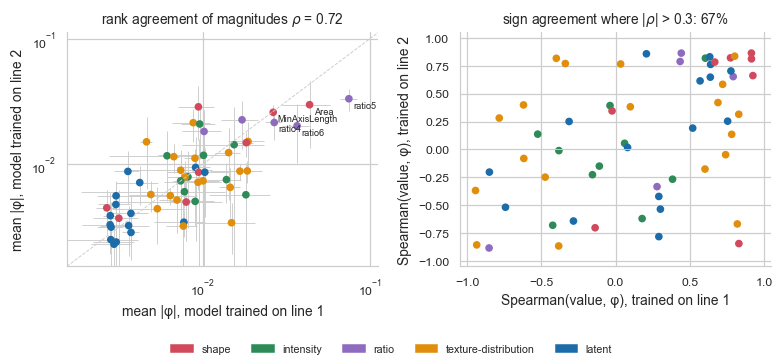

In [13]:
def seed_rho(m):                                                        # mean pairwise Spearman of mean |φ| between seeds
    c = m.T.corr("spearman").to_numpy(); return c[np.triu_indices_from(c, 1)].mean()

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3))
ax = axes[0]; x, y = imp.HO2_mean_abs_phi, imp.HO1_mean_abs_phi            # HO2 = trained on line 1
ax.errorbar(x, y, xerr=imp.HO2_sd_seeds, yerr=imp.HO1_sd_seeds, fmt="none", ecolor="0.8", lw=0.6, zorder=0)
ax.scatter(x, y, c=imp.block.map(C_BLOCK), s=16)
for f in (x.rank(ascending=False) + y.rank(ascending=False)).nsmallest(5).index:
    ax.annotate(f, (x[f], y[f]), fontsize=6, xytext=(3, -6), textcoords="offset points")
rho_mag = spearmanr(x, y)[0]; rho_sgn = spearmanr(imp.HO2_mean_phi, imp.HO1_mean_phi)[0]
lo, hi = min(x.min(), y.min()) / 1.5, max(x.max(), y.max()) * 1.5                # log axes: magnitudes span decades
ax.plot([lo, hi], [lo, hi], color="0.8", lw=0.6, ls="--"); ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi))
ax.set_xlabel("mean |φ|, model trained on line 1"); ax.set_ylabel("mean |φ|, model trained on line 2")
ax.set_title(rf"rank agreement of magnitudes $\rho$ = {rho_mag:.2f}")
ax = axes[1]
x, y = imp.HO2_rho_z_phi, imp.HO1_rho_z_phi
ax.scatter(x, y, c=imp.block.map(C_BLOCK), s=16); ax.axhline(0, color="0.8", lw=0.6); ax.axvline(0, color="0.8", lw=0.6)
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
ax.set_xlabel("Spearman(value, φ), trained on line 1"); ax.set_ylabel("Spearman(value, φ), trained on line 2")
ax.set_title(f"sign agreement where |$\\rho$| > 0.3: {(np.sign(x) == np.sign(y))[(x.abs() > .3) | (y.abs() > .3)].mean():.0%}")
fig.tight_layout(rect=(0, 0.07, 1, 1)); block_legend(fig, ncol=5, loc="lower center", fontsize=7)
savefig(fig, "S2_shapley_score_between_directions")
agree = pd.DataFrame({"rho_magnitude": [rho_mag], "rho_mean_signed_phi": [rho_sgn],
                      **{f"rho_between_seeds_HO{ho}": [seed_rho(per_run.xs(ho))] for ho in (1, 2)}}, index=["Shapley, mean |φ|"])
savetab(agree, "shapley_score_agreement"); agree.round(2)

**3c. How the contributions build the trajectory.** Exact block Shapley values per passage (bag mean over
seeds). The bars of a passage sum to the black line, the predicted score minus the training-line baseline, so
the figure shows which feature blocks carry the held-out line up the score scale and where they disagree.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S3_shapley_blocks_by_passage.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\shapley_score_blocks_by_passage.csv


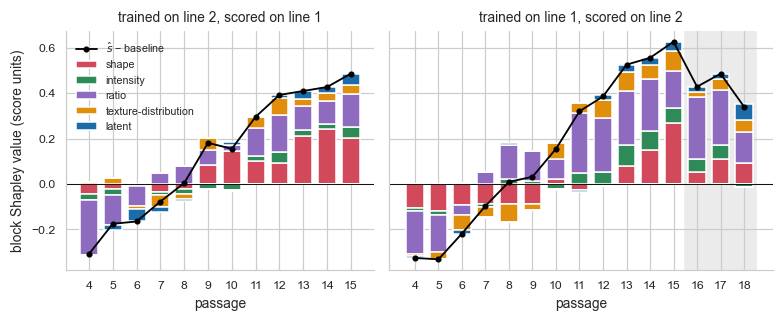

In [14]:
bcols = [f"blk_{b}" for b in BLOCKS]
bp = sh.groupby(["held_out_line", "passage"])[bcols + ["s_hat", "base"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True, gridspec_kw={"width_ratios": [12, 15]})
for ax, ho in zip(axes, (1, 2)):
    d = bp.xs(ho); p = d.index.to_numpy(); pos, neg = np.zeros(len(p)), np.zeros(len(p))
    for b in BLOCKS:
        v = d[f"blk_{b}"].to_numpy()
        ax.bar(p, np.where(v > 0, v, 0), bottom=pos, color=C_BLOCK[b], width=0.75, label=b)
        ax.bar(p, np.where(v < 0, v, 0), bottom=neg, color=C_BLOCK[b], width=0.75)
        pos += np.where(v > 0, v, 0); neg += np.where(v < 0, v, 0)
    ax.plot(p, d.s_hat - d.base, "k-o", ms=3, lw=1.2, label=r"$\hat{s}$ − baseline")
    ax.axhline(0, color="k", lw=0.6); ax.set_xticks(p); ax.set_xlabel("passage")
    if ho == 2: ax.axvspan(15.5, 18.5, color="0.92", zorder=0)
    ax.set_title(f"trained on line {3 - ho}, scored on line {ho}")
axes[0].set_ylabel("block Shapley value (score units)"); axes[0].legend(loc="upper left", fontsize=7)
fig.tight_layout(); savefig(fig, "S3_shapley_blocks_by_passage")
savetab(bp.round(4).reset_index(), "shapley_score_blocks_by_passage", index=False)

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S4_shapley_features_by_passage.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\shapley_score_features_by_passage.csv


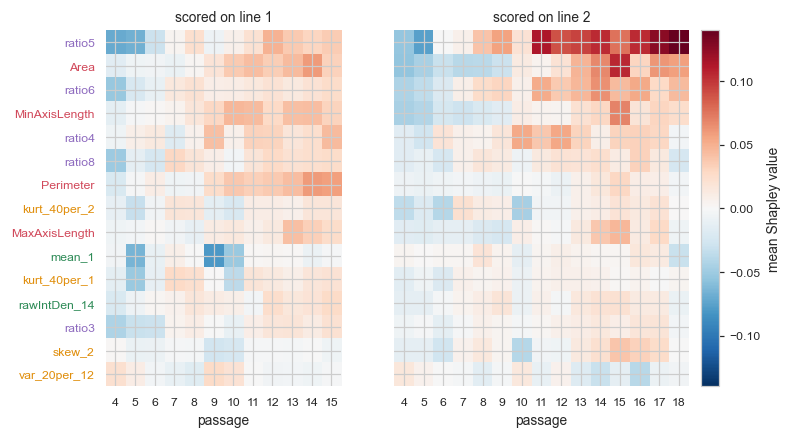

In [15]:
# Per-feature contributions along the trajectory: mean φ per passage for the top features
N_HM = 15
top_hm = (imp.HO1_mean_abs_phi + imp.HO2_mean_abs_phi).nlargest(N_HM).index
fp = pd.DataFrame(PHI, columns=FEATS).groupby([sh.held_out_line, sh.passage]).mean()
vmax = np.abs(fp[top_hm].to_numpy()).max()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 0.2 * N_HM + 1.2), sharey=True, gridspec_kw={"width_ratios": [12, 15]})
for ax, ho in zip(axes, (1, 2)):
    d = fp.xs(ho)[top_hm].T
    im = ax.imshow(d.to_numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(d.shape[1])); ax.set_xticklabels(d.columns); ax.set_xlabel("passage")
    ax.set_title(f"scored on line {ho}"); ax.spines[:].set_visible(False)
axes[0].set_yticks(range(N_HM)); axes[0].set_yticklabels(top_hm)
for t, f in zip(axes[0].get_yticklabels(), top_hm): t.set_color(C_BLOCK[block_of(f)])
fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, label="mean Shapley value")
savefig(fig, "S4_shapley_features_by_passage")
savetab(fp.round(5).reset_index(), "shapley_score_features_by_passage", index=False)

**3d. Dependence.** Shapley value of the four leading features against the bag's mean value of that feature,
coloured by passage. A monotone curve that is the same in both directions is a transferable marker; curves that
differ between directions point to line-specific use.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S5_shapley_dependence_top4.png/.pdf


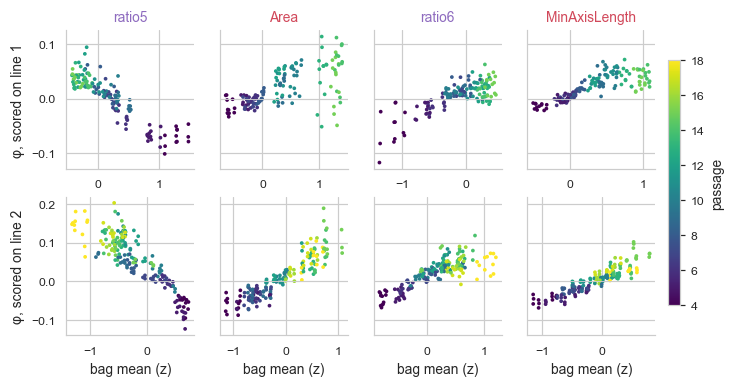

In [16]:
top4 = (imp.HO1_mean_abs_phi + imp.HO2_mean_abs_phi).nlargest(4).index
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.6), sharey="row")
norm = mpl.colors.Normalize(4, 18)
for i, ho in enumerate((1, 2)):
    m = sh.held_out_line.eq(ho).to_numpy()
    for k, f in enumerate(top4):
        ax, j = axes[i, k], FEATS.index(f)
        ax.scatter(ZB[m, j], PHI[m, j], c=sh.passage[m], cmap="viridis", norm=norm, s=6, lw=0)
        ax.axhline(0, color="0.8", lw=0.6)
        if i == 0: ax.set_title(f, color=C_BLOCK[block_of(f)])
        if i == 1: ax.set_xlabel("bag mean (z)")
    axes[i, 0].set_ylabel(f"φ, scored on line {ho}")
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=axes, fraction=0.02, pad=0.02, label="passage")
savefig(fig, "S5_shapley_dependence_top4")

# 4 · Shapley values of the attention score

The gated-attention score $w^\top(\tanh(Vh_i)\odot\sigma(Uh_i))$ is a function of cell $i$ alone, so its Shapley
values are computed exactly on the MIL model's attention branch, with `N_BG_CELLS` training-line cells as
background. This replaces the LightGBM surrogate of the earlier version: there is no fit quality to report because
nothing is approximated except the permutation sampling. Positive values raise the cell's attention relative to
an average training-line cell.

In [17]:
def shapley_attention_run(r, seed=0):
    f = SHAP_DIR / f"shapley_attention_{r['rid']}.csv"
    if f.exists() and not RECOMPUTE: return pd.read_csv(f)
    rng = np.random.default_rng(seed); Zt = T(r["Z"])
    cells = rng.choice(np.where(lab.cell_line.eq(r["ho"]))[0], N_ATT_CELLS, replace=False)
    bg = Zt[torch.as_tensor(rng.choice(np.where(lab.cell_line.eq(r["train"]))[0], N_BG_CELLS, replace=False), device=DEVICE)]
    rows = []
    for c in cells:
        x = Zt[c]
        v = lambda M: attention_logit(r, torch.where(M[:, None, :], x[None, None], bg[None]).reshape(-1, D)).reshape(len(M), -1).mean(1)
        phi, base, full = bag_shapley(v, rng)
        rows.append({"run_id": r["rid"], "held_out_line": r["ho"], "seed": r["seed"], "cell": c, "passage": lab.passage[c], "base": base, "logit": full}
                    | {f"phi_{f}": x_ for f, x_ in zip(FEATS, phi)})
    df = pd.DataFrame(rows); df.to_csv(f, index=False); return df

sha = pd.concat([shapley_attention_run(r) for r in runs.values()], ignore_index=True)
PHA, ZA = sha[[f"phi_{f}" for f in FEATS]].to_numpy(), np.stack([runs[rid]["Z"][c] for rid, c in zip(sha.run_id, sha.cell)])
imp_a = pd.DataFrame({f"HO{ho}_mean_abs_phi": pd.DataFrame(np.abs(PHA[sha.held_out_line.eq(ho)]), columns=FEATS).mean() for ho in (1, 2)})
imp_a["block"] = [block_of(f) for f in FEATS]; imp_a = imp_a.sort_values("HO1_mean_abs_phi", ascending=False)
savetab(imp_a.round(5), "shapley_attention_feature_importance")
print(f"cells explained: {len(sha)} | attention-logit SD across held-out cells: {sha.logit.std():.3f}")
imp_a.head(12).round(4)

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\shapley_attention_feature_importance.csv
cells explained: 1200 | attention-logit SD across held-out cells: 0.268


,HO1_mean_abs_phi,HO2_mean_abs_phi,block
ratio4,0.0425,0.0503,ratio
latent_3,0.0422,0.0109,latent
latent_4,0.0404,0.0156,latent
Circularity,0.0395,0.0247,shape
rawIntDen_12,0.0358,0.0159,intensity
Perimeter,0.0318,0.0120,shape
mean_3,0.0315,0.0139,intensity
skew_40per_3,0.0313,0.0141,texture-distribution
skew_4,0.0312,0.0091,texture-distribution
latent_15,0.0309,0.0157,latent


saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S6_shapley_attention_beeswarm.png/.pdf


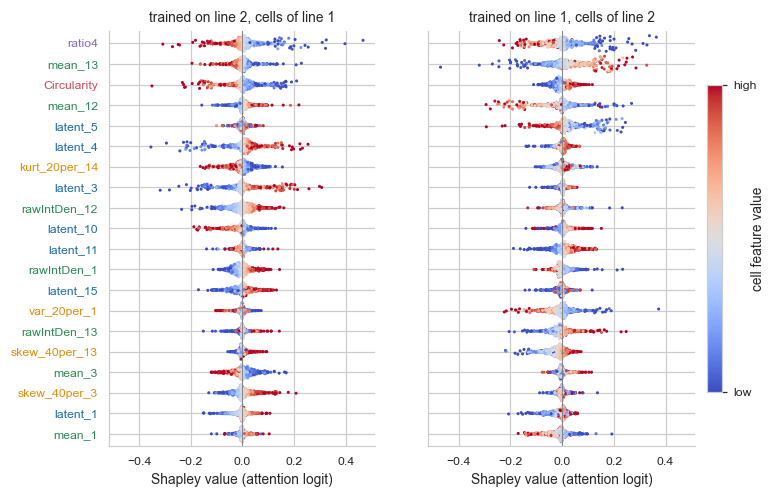

In [18]:
order_a = (imp_a.HO1_mean_abs_phi + imp_a.HO2_mean_abs_phi).sort_values(ascending=False).index[:N_TOP][::-1]
jj = [FEATS.index(f) for f in order_a]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 0.19 * N_TOP + 1.1), sharey=True, sharex=True)
for ax, ho in zip(axes, (1, 2)):
    m = sha.held_out_line.eq(ho).to_numpy(); beeswarm(ax, PHA[m], ZA[m], jj)
    ax.set_title(f"trained on line {3 - ho}, cells of line {ho}"); ax.set_xlabel("Shapley value (attention logit)")
axes[0].set_yticklabels(order_a)
for t, f in zip(axes[0].get_yticklabels(), order_a): t.set_color(C_BLOCK[block_of(f)])
cb = fig.colorbar(mpl.cm.ScalarMappable(cmap="coolwarm"), ax=axes, fraction=0.025, pad=0.02, ticks=[0, 1])
cb.ax.set_yticklabels(["low", "high"]); cb.set_label("cell feature value", labelpad=-4)
savefig(fig, "S6_shapley_attention_beeswarm")

# 5 · Do the features that set the score also set attention?

Mean |φ| for the bag score (section 3) against mean |φ| for the attention logit (section 4), per direction. Both
are in z-unit input space, so manual and latent features sit on the same axes. A strong positive rank correlation
means the model attends to cells that are extreme in the same features that move the score; a weak one means a
division of labour between the encoder-and-head path and the pooling weights.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\S7_score_vs_attention_shapley.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\score_vs_attention_shapley.csv


,rho_all,rho_shape,rho_intensity,rho_ratio,rho_texture-distribution,rho_latent
held_out_line,,,,,,
1,0.28,0.67,-0.12,-0.1,0.46,0.52
2,0.25,0.10,0.53,0.5,0.43,0.27


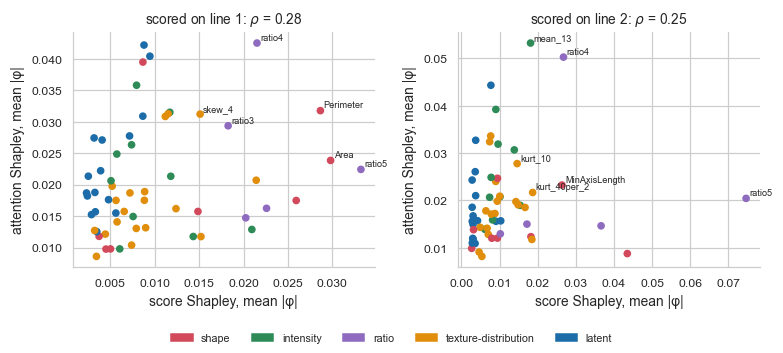

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
rows = []
for ax, ho in zip(axes, (1, 2)):
    x, y = imp[f"HO{ho}_mean_abs_phi"], imp_a.loc[imp.index, f"HO{ho}_mean_abs_phi"]
    ax.scatter(x, y, c=imp.block.map(C_BLOCK), s=16)
    for f in (x.rank(ascending=False) + y.rank(ascending=False)).nsmallest(6).index:
        ax.annotate(f, (x[f], y[f]), fontsize=6, xytext=(2, 2), textcoords="offset points")
    r_all = spearmanr(x, y)[0]; rows.append({"held_out_line": ho, "rho_all": r_all}
                                            | {f"rho_{b}": spearmanr(x[imp.block == b], y[imp.block == b])[0] for b in BLOCKS if (imp.block == b).sum() >= 4})
    ax.set_xlabel("score Shapley, mean |φ|"); ax.set_ylabel("attention Shapley, mean |φ|")
    ax.set_title(rf"scored on line {ho}: $\rho$ = {r_all:.2f}")
fig.tight_layout(rect=(0, 0.07, 1, 1)); block_legend(fig, ncol=5, loc="lower center", fontsize=7)
savefig(fig, "S7_score_vs_attention_shapley")
link = pd.DataFrame(rows).set_index("held_out_line"); savetab(link.round(3), "score_vs_attention_shapley"); link.round(2)

## Files written

In [20]:
for d in (FIG_DIR, TAB_DIR, SHAP_DIR):
    print(d); [print("  ", p.name) for p in sorted(d.iterdir()) if p.suffix in (".png", ".csv") and re.match(r"(B[45]|S\d|shapley|attention|score_vs)", p.name)]

C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4
   B4_attention_distribution_task1.png
   B5_attention_drivers_task1.png
   S1_shapley_score_beeswarm.png
   S2_shapley_score_between_directions.png
   S3_shapley_blocks_by_passage.png
   S4_shapley_features_by_passage.png
   S5_shapley_dependence_top4.png
   S6_shapley_attention_beeswarm.png
   S7_score_vs_attention_shapley.png
C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4
   attention_drivers_task1.csv
   attention_relative_quantiles_task1.csv
   score_vs_attention_shapley.csv
   shapley_attention_feature_importance.csv
   shapley_score_agreement.csv
   shapley_score_block_share.csv
   shapley_score_blocks_by_passage.csv
   shapley_score_feature_importance.csv
   shapley_score_features_by_passage.csv
C:\Users\goofy\PycharmProjects\MILAgeScore\outputs\review\shapley
   attention_loco_HO_L1_seed0.csv
   attention_loco_HO_L1_seed1.csv
   attention_loco_HO_L1_seed2.csv
   attention_loco_HO_L2_seed0.csv